**MSCS 634 – Lab 5: Hierarchical and DBSCAN Clustering**

**Student: Anusha Sharma**

**Course: Advanced Big Data and Data Mining (MSCS-634)**

**Assignment: Lab 5 – Hierarchical and DBSCAN Clustering**

**1. Data pre-processing and exploration**


Import the Wine dataset, examine the attributes, and normalize the numeric attributes. PCA is only applied for visualizing the dataset in 2D space, while clustering is done on the 13-dimensional normalized dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from scipy.cluster.hierarchy import linkage, dendrogram

wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target
print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
display(df.head())
df.info()
display(df.describe())

Dataset shape: (178, 13)
Missing values: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: fl

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
X_pca = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
print("Standardized data shape:", X_scaled.shape)

Standardized data shape: (178, 13)


**2. Agglomerative Hierarchical Clustering**


Cluster numbers 2 to 6 can be compared using Ward linkage and silhouette score.
The Wine Labels are known for external validation and not for fitting.


In [3]:
hier_results = []
hier_labels = {}
for k in range(2, 7):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
    hier_labels[k] = labels
    hier_results.append({"n_clusters": k, "silhouette": silhouette_score(X_scaled, labels), "homogeneity": homogeneity_score(y_true, labels), "completeness": completeness_score(y_true, labels)})
hier_table = pd.DataFrame(hier_results)
display(hier_table.round(3))
best_k = int(hier_table.loc[hier_table.silhouette.idxmax(), "n_clusters"])
print("Best k by silhouette:", best_k)

,n_clusters,silhouette,homogeneity,completeness
0,2,0.267,0.444,0.774
1,3,0.277,0.790,0.783
2,4,0.226,0.790,0.649
3,5,0.187,0.811,0.576
4,6,0.180,0.835,0.553


Best k by silhouette: 3


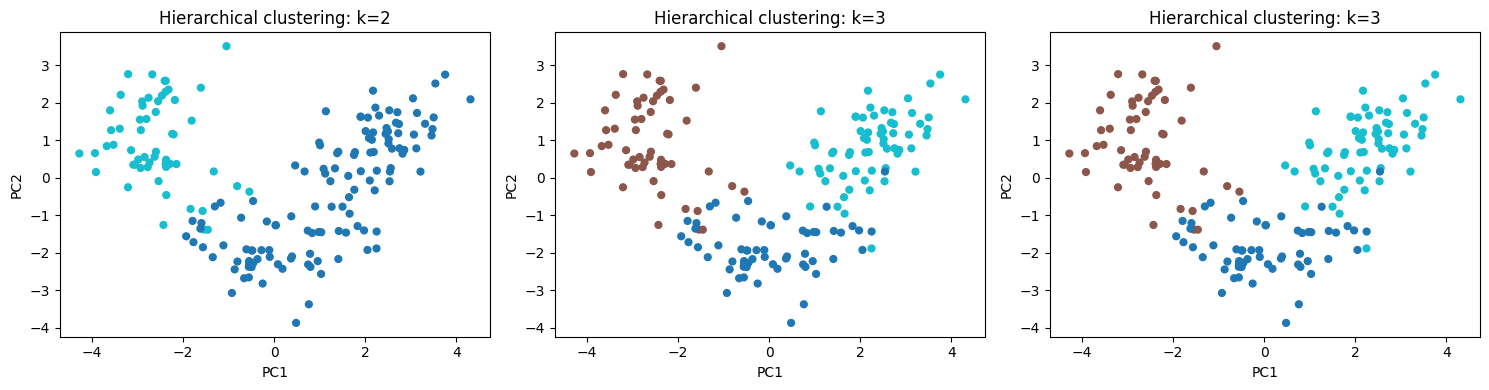

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, [2, 3, best_k]):
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=hier_labels[k], cmap="tab10", s=24)
    ax.set(title=f"Hierarchical clustering: k={k}", xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.show()

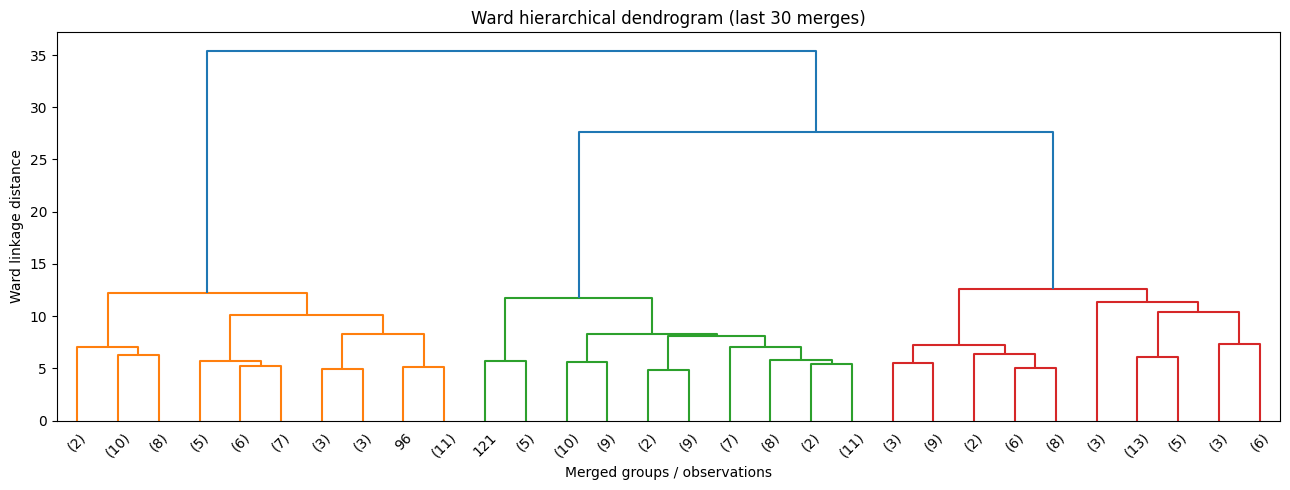

In [5]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True)
plt.title("Ward hierarchical dendrogram (last 30 merges)")
plt.xlabel("Merged groups / observations")
plt.ylabel("Ward linkage distance")
plt.tight_layout(); plt.show()

Interpreting the dendrogram: The vertical height denotes the amount of dissimilarity between merging clusters. Large gaps in vertical distances can give hints about possible cutting heights and the number of clusters.
This is a truncated version of the dendrogram that represents only the final merging clusters and not the 178 leaves.

**3. DBSCAN parameter experimentation**


Test different values for the neighborhood radius and the minimum number of neighbors. If the class label equals -1, it is considered noise. The silhouette score is calculated only when there are at least two clusters which are not considered noise.

In [7]:
db_results = []
db_labels = {}
for eps in [1.5, 2.0, 2.2, 2.3, 2.4, 2.5, 3.0, 3.5, 4.0, 4.5]:
    for min_samples in [3, 5, 8]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        db_labels[(eps, min_samples)] = labels
        mask = labels != -1
        cluster_count = len(set(labels[mask]))
        noise_count = int((~mask).sum())
        sil = np.nan
        if cluster_count >= 2 and mask.sum() > cluster_count:
            sil = silhouette_score(X_scaled[mask], labels[mask])
        db_results.append({"eps": eps, "min_samples": min_samples, "clusters": cluster_count, "noise": noise_count, "silhouette_nonnoise": sil, "homogeneity": homogeneity_score(y_true, labels), "completeness": completeness_score(y_true, labels)})
db_table = pd.DataFrame(db_results)
display(db_table.round(3))

,eps,min_samples,clusters,noise,silhouette_nonnoise,homogeneity,completeness
0,1.5,3,8,147,0.331,0.189,0.251
1,1.5,5,0,178,NaN,0.000,1.000
2,1.5,8,0,178,NaN,0.000,1.000
3,2.0,3,5,64,0.211,0.442,0.372
4,2.0,5,5,85,0.240,0.362,0.325
5,2.0,8,3,117,0.436,0.390,0.469
6,2.2,3,3,44,0.073,0.486,0.481
7,2.2,5,2,55,0.348,0.410,0.428
8,2.2,8,2,67,0.350,0.371,0.390
9,2.3,3,3,32,0.225,0.493,0.512


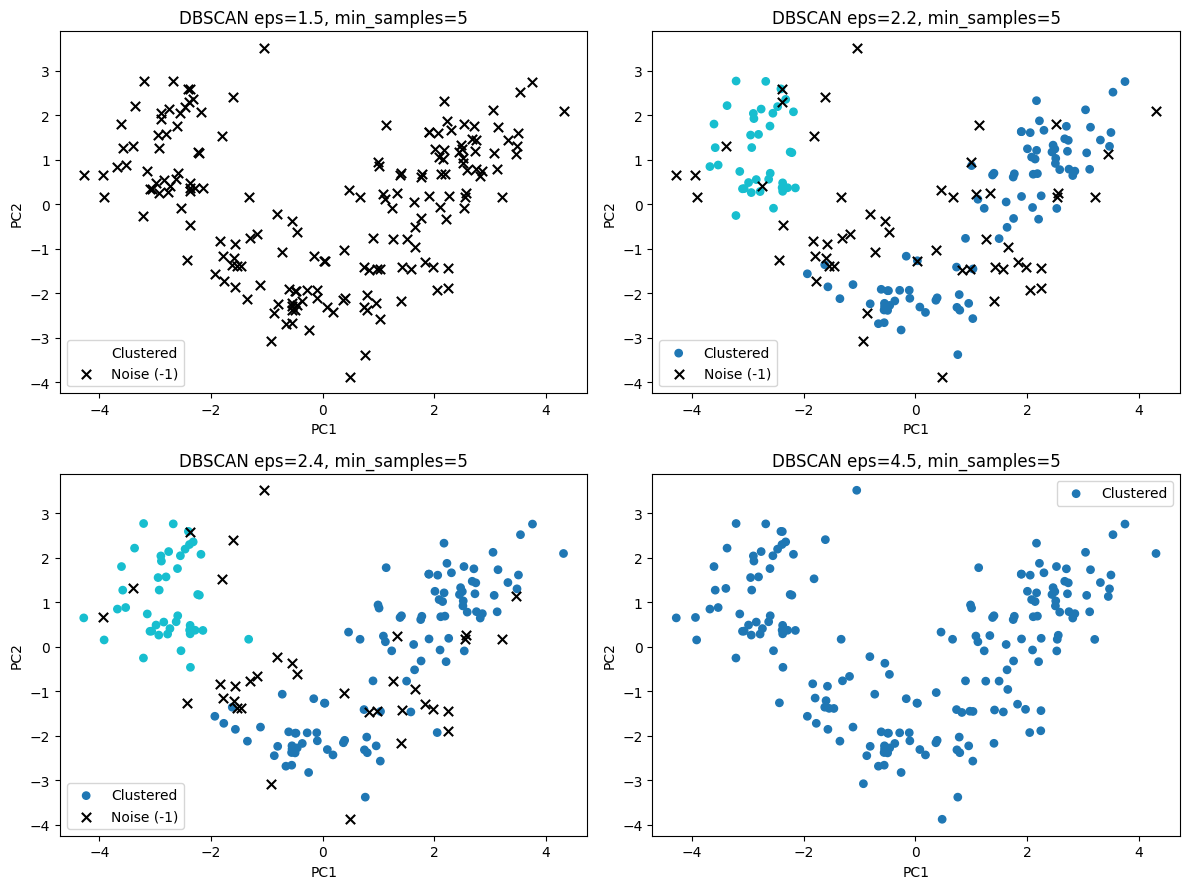

In [8]:
examples = [(1.5, 5), (2.2, 5), (2.4, 5), (4.5, 5)]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, params in zip(axes.flat, examples):
    labels = db_labels[params]
    noise = labels == -1
    ax.scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=labels[~noise], cmap="tab10", s=28, label="Clustered")
    if noise.any():
        ax.scatter(X_pca[noise, 0], X_pca[noise, 1], c="black", marker="x", s=45, label="Noise (-1)")
    ax.set(title=f"DBSCAN eps={params[0]}, min_samples={params[1]}", xlabel="PC1", ylabel="PC2")
    ax.legend()
plt.tight_layout(); plt.show()

**4. Results and interpretation**

In [9]:
print("Hierarchical results (sorted by silhouette):")
display(hier_table.sort_values("silhouette", ascending=False).round(3))
print("DBSCAN configurations with at least two non-noise clusters:")
valid = db_table.dropna(subset=["silhouette_nonnoise"])
if valid.empty:
    print("None in this parameter grid. Expand the search or report the limitation.")
else:
    display(valid.sort_values("silhouette_nonnoise", ascending=False).round(3))
print("Note: DBSCAN silhouette excludes noise, so compare it cautiously with hierarchical silhouette.")

Hierarchical results (sorted by silhouette):


,n_clusters,silhouette,homogeneity,completeness
1,3,0.277,0.790,0.783
0,2,0.267,0.444,0.774
2,4,0.226,0.790,0.649
3,5,0.187,0.811,0.576
4,6,0.180,0.835,0.553


DBSCAN configurations with at least two non-noise clusters:


,eps,min_samples,clusters,noise,silhouette_nonnoise,homogeneity,completeness
5,2.0,8,3,117,0.436,0.390,0.469
8,2.2,8,2,67,0.350,0.371,0.390
7,2.2,5,2,55,0.348,0.410,0.428
11,2.3,8,2,52,0.342,0.404,0.427
14,2.4,8,2,43,0.335,0.453,0.488
0,1.5,3,8,147,0.331,0.189,0.251
10,2.3,5,2,42,0.331,0.462,0.492
13,2.4,5,2,36,0.327,0.504,0.552
17,2.5,8,2,30,0.318,0.484,0.545
12,2.4,3,2,28,0.314,0.487,0.549


Note: DBSCAN silhouette excludes noise, so compare it cautiously with hierarchical silhouette.


**Discussion **
Hierarchical clustering: State the best n_clusters, silhouette, homogeneity, and completeness values from the table. Explain what the dendrogram shows and whether the PCA scatter plots indicate clear separation between clusters.

**DBSCAN:** Explain how larger eps tends to link more observations while decreasing noise and how larger min_samples tends to be stricter about density. Use specific rows from the output for illustration; don’t assume that every pair will generate multiple clusters.

**Comparison:** Hierarchical clustering always clusters all observations and needs to choose the number of clusters. DBSCAN can detect noise and doesn’t need to choose the number of clusters upfront, but is sensitive to eps and min_samples, especially in 13-dimensional data. The silhouette score of DBSCAN is calculated based only on non-noise observations.

**Conclusion:** Indicate which clustering algorithm performed better for your chosen criterion and explain the reasons. External homogeneity/completeness criteria use the dataset labels only for validation. PCA is just visualization and may distort separation.